# Adversarial Search: Solving Tic-Tac-Toe with Monte Carlo Tree Search

## Introduction 

Multiplayer games can be implemented as:
1. Nondeterministic actions: The opponent is seen as part of an environment with nondeterministic actions. Non-determinism is the result of the unknown opponent's moves. 
2. Optimal Decisions: Minimax search (search complete game tree) and alpha-beta pruning.
3. Heuristic Alpha-Beta Tree Search: Cut off tree search and use heuristic to estimate state value. 
4. __Monte Carlo Search:__ Simulate playouts to estimate state value. 

Here we will implement search for Tic-Tac-Toe (see [rules](https://en.wikipedia.org/wiki/Tic-tac-toe)). The game is a __zero-sum game__: Win by x results in +1, win by o in -1 and a tie has a value of 0. Max plays x and tries to maximize the outcome while Min plays o and tries to minimize the outcome.   

We will implement
* We enhance Pure Monte Carlo Search by using the upper confidence bound (UCB1) selection policy. That is, we use UCB1 to determine for which action to perform the next playout. This will allow the algorithm to focus on actions here it needs to collect more information. Note that complete Upper Confidence Bounds applied to Trees (UCT) creates a tree and the expand step in the code needs to be added. The tree branch for the chosen move is preserved and used for future moves.

The code for the basic functions used for search are implemented in [tictactoe.py](tictactoe.py). 

In [1]:
# download if missing
import urllib.request
import os
import numpy as np
np.random.seed(42)

def download(file, base_url):
    if not os.path.exists(file):
        urllib.request.urlretrieve(base_url + file, file)

download("tictactoe.py", ".")

In [2]:
from tictactoe import empty_board, actions, result, terminal, utility, other, show_board
from tictactoe import random_player, play 

# Monte Carlo Search with Upper Confidence Bound

See AIMA page 163. 

We enhance pure Monte Carlo Search by using UCB1 as a __selection policy__. This can be seen as a 
restricted version of UTC: 
* Only build a tree of depth 1 and use the UBC1 selection policy.
* Use a random playout policy.


__Note on the playout policy:__ We use here a random playout policy, which ends up creating just a randomized search that works fine for this toy problem. For real applications you need to extend the code with a good __playout policy__ (e.g., manually created heuristics or a neural [network learned by self-play using reinforcement learning](https://towardsdatascience.com/how-to-teach-an-ai-to-play-games-deep-reinforcement-learning-28f9b920440a)).

## Simulate playouts

In [3]:
import numpy as np

def playout(state, action, player = 'x'):
    """Perform a random playout starting with the given action on the given board 
    and return the utility of the finished game."""
    state = result(state, player, action)
    current_player = other(player)
    
    while(True):
        # reached terminal state?
        u = utility(state, player)
        if u is not None: 
            return u
        
        # we use a random playout policy
        a = np.random.choice(actions(state))
        state = result(state, current_player, a)
        #print(state)
        
        # switch between players
        current_player = other(current_player)


board = empty_board()
print(playout(board, 0))
print(playout(board, 0))
print(playout(board, 0))

-1
1
-1


**Nhận xét:** `playout` đi ngẫu nhiên đến hết ván rồi trả về utility (+1 thắng, 0 hòa, −1 thua) theo góc nhìn của người đi nước đầu tiên (`player`). Ba lần chạy cho 3 giá trị khác nhau nên kết quả của một playout rất nhiễu; phải lấy trung bình nhiều playout mới ước lượng được giá trị của nước đi.

## Upper Confidence Bound Applied to Trees (Restricted to Depth 1)

In [4]:
import pandas as pd
import math

DEBUG = 1

def UCT_depth1(board, N = 100, player = 'x'):
    """Upper Confidence bound applied to Trees for limited tree depth of 1. 
    Simulation budget is N playouts."""
    global DEBUG
    
    C = math.sqrt(2) # tradeoff constant
    
    # the tree is 1 action deep
    acts = actions(board)
    
    u = [0] * len(acts) # total utility through actions
    n = [0] * len(acts) # number of playouts through actions
    n_parent = 0 # total playouts so far (i.e., number of playouts through parent)
    
    # make sure we try each action once
    UCB1 = [+math.inf] * len(acts) 
    
    for i in range(N):

        # Select
        action_id = UCB1.index(max(UCB1))
    
        # Expand
        # UTC would expand the tree. We keep the tree at depth 1, essentially performing
        # Pure Monte Carlo search with an added UCB1 selection policy. 
        
        # Simulate
        p = playout(board, acts[action_id], player = player)
    
        # Back-Propagate (i.e., update counts and UCB1)
        u[action_id] += p
        n[action_id] += 1
        n_parent += 1
        
        for action_id in range(len(acts)):
            if n[action_id] > 0:
                UCB1[action_id] = u[action_id] / n[action_id] + C * math.sqrt(math.log(n_parent) / n[action_id])
    
    # return action with largest number of playouts 
    action = acts[n.index(max(n))]
    
    if DEBUG >= 1: 
        print(pd.DataFrame({'action':acts, 
                            'total utility':u, 
                            '# of playouts':n, 
                            'UCB1':UCB1}))
        print()
        print(f"Best action: {action}")
    
    
    return action

In [5]:
board = empty_board()
display(board)

%timeit -n 1 -r 1 UCT_depth1(board, N = 1000)

[' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ']

   action  total utility  # of playouts      UCB1
0       0              6             46  0.678465
1       1              4             42  0.668772
2       2              6             42  0.716391
3       3             -2             24  0.675380
4       4            351            635  0.700257
5       5              5             42  0.692581
6       6             19             72  0.701932
7       7             19             74  0.688840
8       8             -2             23  0.688075

Best action: 4
361 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


**Nhận xét (bàn rỗng, N = 1000):** UCB1 dồn phần lớn playout vào ô giữa (ô 4 được khoảng 635/1000 lần, utility trung bình ≈ 0,55), còn mỗi ô khác chỉ được khoảng 23–74 lần. Đây là dấu hiệu của *exploitation*: sau khi thấy ô 4 cho utility trung bình cao nhất thì thuật toán liên tục quay lại ô đó. Mỗi ô khác vẫn được thử ít nhất vài chục lần (*exploration*). Thời gian chạy khoảng 0,1–0,2 giây cho 1000 playout.

## Some Tests

### x is about to win (play 8)

Board:


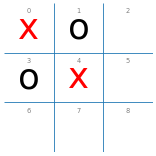


   action  total utility  # of playouts      UCB1
0       2             18             21  1.519402
1       5             14             17  1.559590
2       6             14             17  1.559590
3       7             13             16  1.571214
4       8             29             29  1.563558

Best action: 8
18 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


In [6]:
board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[3] = 'o'
board[4] = 'x'

print("Board:")
show_board(board)

print()
%timeit -n1 -r1 UCT_depth1(board)

**Nhận xét (x sắp thắng, N = 100):** UCB1 chọn ô 8 – đúng nước thắng ngay (đường chéo 0–4–8). Ô 8 có utility trung bình = 1,0 (29 playout, cả 29 đều thắng, vì thắng ngay nên playout nào cũng là +1) nên UCB1 của nó cao nhất và nó nhận nhiều playout nhất (29/100). Các ô 2, 5, 6, 7 chỉ nhận 16–21 playout. Với N nhỏ như 100, độ chênh về số playout chưa lớn, đó là lý do trường hợp này cần N lớn hơn thì quyết định mới chắc chắn.

### o is about to win

Board:


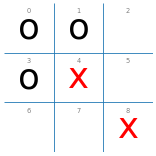


   action  total utility  # of playouts      UCB1
0       2              3            413  0.190162
1       5            -12             14  0.136246
2       6              5            553  0.167101
3       7            -14             20  0.131129

Best action: 6
116 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


In [7]:
board = empty_board() 
board[0] = 'o'
board[1] = 'o'
board[3] = 'o'
board[4] = 'x'
board[8] = 'x'

print("Board:")
show_board(board)

print()
%timeit -n1 -r1 UCT_depth1(board, N = 1000)

**Nhận xét (o sắp thắng, N = 1000):** thế này x thật ra đã thua (o có hai mối đe dọa: ô 2 và ô 6), nên mọi nước đều có giá trị minimax −1. UCB1 chọn ô 6 và dồn rất nhiều playout vào ô 2 (413) và ô 6 (553), còn ô 5 và 7 chỉ được 14 và 20. Lý do: ô 2 và ô 6 là hai nước *chặn bớt một mối đe dọa*; khi đó o (chơi ngẫu nhiên trong playout) có xác suất bỏ lỡ nước thắng còn lại, nên utility trung bình xấp xỉ 0 (5/553 và 3/413), trong khi ô 5, 7 cho utility trung bình khoảng −0,7 đến −0,86. UCB1 tìm ra đúng nước "ít tệ nhất" so với một đối thủ không hoàn hảo. Cần nhớ là Monte Carlo ước lượng giá trị *so với đối thủ ngẫu nhiên*, không phải giá trị minimax.

### x can draw if it chooses 7

Board:


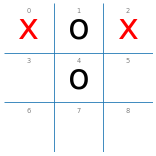


   action  total utility  # of playouts      UCB1
0       3            -10             89  0.281633
1       5            -13             47  0.265573
2       6            -11             20  0.281129
3       7            130            817  0.289157
4       8            -12             27  0.270878

Best action: 7
221 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


In [8]:
board = empty_board() 
board[0] = 'x'
board[1] = 'o'
board[2] = 'x'
board[4] = 'o'

print("Board:")
show_board(board)

print()
%timeit -n1 -r1 UCT_depth1(board, N = 1000)

**Nhận xét (x chỉ hòa nếu đánh ô 7, N = 1000):** UCB1 chọn ô 7 đúng như nước chặn bắt buộc (cột 1–4–7). Ô 7 nhận 817/1000 playout với utility trung bình ≈ 0,16, các ô còn lại 20–89 playout và utility trung bình âm. Nếu không chặn thì o thắng ngay nên các playout đó cho kết quả thấp, thuật toán sớm bỏ các nước này.

### Empty board: Only a draw an be guaranteed

Board:


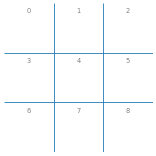


   action  total utility  # of playouts      UCB1
0       0              4             13  1.149409
1       1             -2              4  1.017427
2       2             13             23  1.198028
3       3             -1              5  1.157228
4       4              1              9  1.122729
5       5              2             11  1.096861
6       6              6             16  1.133714
7       7             -1              7  1.004210
8       8              3             12  1.126087

Best action: 2
55.5 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)
   action  total utility  # of playouts      UCB1
0       0            142            370  0.598351
1       1             30            128  0.599178
2       2             58            194  0.595290
3       3             25            115  0.602262
4       4           2054           3825  0.603728
5       5             28            123  0.599786
6       6             -5             28  0.601410
7       7         

In [9]:
board = empty_board() 

print("Board:")
show_board(board)


print()
%timeit -n1 -r1 UCT_depth1(board, N = 100)
%timeit -n1 -r1 UCT_depth1(board, N = 5000)

**Nhận xét (bàn rỗng):** với N = 100 UCB1 chọn ô 2 (ô góc) với chỉ 23 playout và các ô khác có số playout rất gần nhau (4–16): chưa đủ dữ liệu nên kết quả không ổn định. Với N = 5000 nó chọn ô 4 (ô giữa) với 3825 playout (≈ 76%). Về mặt lý thuyết mọi nước đầu đều hòa nếu hai bên chơi hoàn hảo, nhưng so với đối thủ ngẫu nhiên thì ô giữa có tỉ lệ thắng cao nhất nên Monte Carlo ưu tiên nó. Thời gian tỉ lệ thuận với N (khoảng 35 ms cho N = 100 và 1,3 giây cho N = 5000).

### A bad situation

Board:


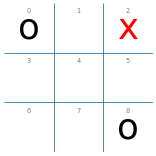


   action  total utility  # of playouts      UCB1
0       1             -7             23  0.328463
1       3             -5              5  0.357228
2       4             -5              5  0.357228
3       5             -5              5  0.357228
4       6             -4             52  0.343935
5       7             -6             10  0.359705

Best action: 6


6

In [10]:
board = empty_board() 
board[0] = 'o'
board[2] = 'x'
board[8] = 'o'

print("Board:")
show_board(board)


print()
display(UCT_depth1(board))

**Nhận xét (tình huống bất lợi):** ở thế này mọi nước của x đều thua nếu o chơi tối ưu (minimax = −1). UCB1 chọn ô 6 với 52/100 playout, vì ô 6 có utility trung bình cao nhất (−4/52 ≈ −0,08); ô 3, 4, 5 chỉ −1,0 (5 playout mỗi ô) và ô 7 là −0,6. Như ghi chú gốc của notebook, o ngẫu nhiên rất ít khi chặn đúng chỗ nên x vẫn có cơ hội thắng nếu đi đúng.

__Note:__ It looks like random player o is very unlikely to block x and take advantage of the trap by playing the bottom left corner!

## Experiments

### Pure Monte Carlo Search vs. Random

In [11]:
def ucb1_10_player(board, player = 'x'):
    action = UCT_depth1(board, N = 10, player = player)
    return action

def ucb1_100_player(board, player = 'x'):
    action = UCT_depth1(board, N = 100, player = player)
    return action

In [12]:
DEBUG = 0
print("UCB1 (10) vs. random:")
%timeit -n1 -r1 display(play(ucb1_10_player, random_player))

print()
print("random vs. UCB1 (10):")
%timeit -n1 -r1 display(play(random_player, ucb1_10_player))

UCB1 (10) vs. random:


{'x': 90, 'o': 7, 'd': 3}

757 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)

random vs. UCB1 (10):


{'x': 20, 'o': 69, 'd': 11}

691 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


**Nhận xét (UCB1 N = 10 vs random, 100 ván):** khi UCB1 đi trước (X) nó thắng 90, thua 7, hòa 3. Khi đi sau (O) nó chỉ thắng 69, thua 20, hòa 11. Lý do: người đi trước có lợi thế, ngay cả khi random đi trước cũng thắng khoảng 60% so với random (xem bảng tổng hợp). Với N = 10 mỗi nước đi chỉ mô phỏng 10 ván nên phần lớn playout bị dùng để thử mỗi nước một lần (9 nước đầu), UCB1 gần như chưa kịp "tập trung".

In [13]:
DEBUG = 0
print("UCB1 (100) vs. random:")
%timeit -n 1 -r 1 display(play(ucb1_100_player, random_player))

print()
print("random vs. UCB1 (100):")
%timeit -n 1 -r 1 display(play(random_player, ucb1_100_player))

UCB1 (100) vs. random:


{'x': 96, 'o': 0, 'd': 4}

9.12 s ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)

random vs. UCB1 (100):


{'x': 7, 'o': 87, 'd': 6}

5.78 s ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


**Nhận xét (UCB1 N = 100 vs random, 100 ván):** đi trước thắng 96, thua 0, hòa 4; đi sau thắng 87, thua 7, hòa 6. Tăng N từ 10 lên 100 làm số ván thua giảm rõ (7→0 khi đi trước, 20→7 khi đi sau). Mỗi 100 ván mất khoảng 4 giây.

In [14]:
DEBUG = 0
print("UCB1 (100) vs. UCB1 (10):")
%timeit -n 1 -r 1 display(play(ucb1_100_player, ucb1_10_player))

print()
print("UCB1 (10) vs. UCB1 (100):")
%timeit -n 1 -r 1 display(play(ucb1_10_player, ucb1_100_player))

UCB1 (100) vs. UCB1 (10):


{'x': 85, 'o': 3, 'd': 12}

7.59 s ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)

UCB1 (10) vs. UCB1 (100):


{'x': 32, 'o': 49, 'd': 19}

6.43 s ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


**Nhận xét (UCB1 100 vs UCB1 10):** UCB1(100) thắng 85/100 khi đi trước và 49/100 khi đi sau (UCB1(10) thắng 32 khi đi trước). Tác tử mạnh hơn (nhiều mô phỏng hơn) thắng ở cả hai vị trí, nhưng lợi thế đi trước vẫn ảnh hưởng mạnh: UCB1(10) đi trước vẫn thắng được 32/100.

## UCB1 và PMCS đấu với Random (cùng ngân sách N)

Các cell gốc ở trên đã chạy `ucb1_10_player` / `ucb1_100_player` đấu với random 1000 ván. Ở đây mình đặt UCB1 và PMCS cạnh nhau, **cùng N**, mỗi bên 300 ván, để so sánh trực tiếp (X = tác tử đi trước, và O = tác tử đi sau).

In [15]:
import time
from tictactoe import check_board

def pmcs_quiet(board, N=100, player='x'):
    """Pure Monte Carlo Search (như notebook pmcs): chia đều N playout."""
    acts = actions(board)
    n = max(1, math.floor(N/len(acts)))
    ps = {a: np.mean([playout(board, a, player) for _ in range(n)]) for a in acts}
    return max(ps, key=ps.get)

def pmcs10(board, player='x'):   return pmcs_quiet(board, 10, player)
def pmcs100(board, player='x'):  return pmcs_quiet(board, 100, player)

def eval_vs_random(agent, side, games):
    res = {'x': 0, 'o': 0, 'd': 0}; t_total = 0.0; moves = 0
    for _ in range(games):
        board = empty_board(); turn = 'x'
        while True:
            t0 = time.perf_counter()
            a = agent(board, turn) if turn == side else random_player(board, turn)
            if turn == side:
                t_total += time.perf_counter() - t0; moves += 1
            board = result(board, turn, a)
            w = check_board(board)
            if w != 'n': res[w] += 1; break
            turn = other(turn)
    return res[side]/games, res['d']/games, res[other(side)]/games, 1000*t_total/moves

rows = []
G = 300
for name, ag in [("PMCS N=10", pmcs10), ("UCB1 N=10", ucb1_10_player), ("PMCS N=100", pmcs100), ("UCB1 N=100", ucb1_100_player)]:
    for side in ['x', 'o']:
        w, d, l, ms = eval_vs_random(ag, side, G)
        rows.append({"tác tử": name, "chơi": side.upper(), "số ván": G, "thắng %": round(100*w, 1),
                     "hòa %": round(100*d, 1), "thua %": round(100*l, 1), "ms/nước đi": round(ms, 2)})
display(pd.DataFrame(rows))

,tác tử,chơi,số ván,thắng %,hòa %,thua %,ms/nước đi
0,PMCS N=10,X,300,89.3,4.0,6.7,2.38
1,PMCS N=10,O,300,70.3,10.0,19.7,1.45
2,UCB1 N=10,X,300,88.3,4.0,7.7,2.45
3,UCB1 N=10,O,300,69.0,12.3,18.7,1.91
4,PMCS N=100,X,300,97.7,2.3,0.0,21.05
5,PMCS N=100,O,300,85.0,8.3,6.7,16.84
6,UCB1 N=100,X,300,99.3,0.7,0.0,19.66
7,UCB1 N=100,O,300,86.3,7.7,6.0,16.29
